<a href="https://colab.research.google.com/github/ywchanna2001/Shoplifting_Detection_Desktop_Application/blob/main/train_yolo26n.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Train YOLO26n for Shoplifting Detection

Trains **YOLO26n** to detect `normal` and `shoplifting` behaviours in shop CCTV frames, then exports it to **ONNX** for the CPU desktop app.

**Before start configure colab environment:**
1. **Runtime → Change runtime type → T4 GPU**
2. Add Roboflow API key as a secret named `ROBOFLOW_API_KEY` and turn on notebook access
3. Fill in the settings in step 2


## 1. Install packages


In [1]:
!pip install -q -U ultralytics roboflow onnx onnxslim onnxruntime

In [2]:
import ultralytics
ultralytics.checks()  # shows the Ultralytics version, Python, PyTorch and GPU

Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 42.7/112.6 GB disk)


## 2. Settings
Edit these values. The Roboflow details are shown in the code snippet on your dataset's **Download / Export** page.

In [3]:
import os
import time
from pathlib import Path

import yaml
from roboflow import Roboflow
from ultralytics import YOLO

# Roboflow project details
RF_WORKSPACE = "channas-workspace"
RF_PROJECT = "shoplifting-detection-oxvwp-ictat"
RF_VERSION = 1

# Experiment settings
RUN_NAME = "yolo26n_v1"   # change for each experiment so results are not overwritten
EPOCHS = 100
IMG_SIZE = 640
PATIENCE = 20             # stop if validation mAP does not improve for 20 epochs
SEED = 42                 # fixed seed so runs can be compared fairly

In [4]:
# Read the API key from a Colab secret, or from an environment variable when running locally.
try:
    from google.colab import userdata
    API_KEY = userdata.get("ROBOFLOW_API_KEY")
except ImportError:
    API_KEY = os.environ["ROBOFLOW_API_KEY"]

print("API key loaded:", bool(API_KEY))

API key loaded: True


## 3. Download the dataset
The `yolov8` export format is the same label format used by all Ultralytics YOLO versions, including YOLO26.

In [7]:
rf = Roboflow(api_key=API_KEY)
dataset = (
    rf.workspace(RF_WORKSPACE)
    .project(RF_PROJECT)
    .version(RF_VERSION)
    .download("yolo26")
)
dataset_dir = Path(dataset.location)
print("Dataset folder:", dataset_dir)

loading Roboflow workspace...
loading Roboflow project...
Dataset folder: /content/Shoplifting-Detection-1


## 4. Check and fix `data.yaml`
Roboflow exports often use relative paths like `../train/images`, which can break. This rewrites them relative to the dataset folder and checks the classes and split sizes.

In [8]:
data_yaml = dataset_dir / "data.yaml"
with open(data_yaml) as f:
    data = yaml.safe_load(f)

data["path"] = str(dataset_dir)
data["train"] = "train/images"
data["val"] = "valid/images"
data["test"] = "test/images"

with open(data_yaml, "w") as f:
    yaml.safe_dump(data, f, sort_keys=False)

print("Classes:", data["names"])
for split in ("train", "valid", "test"):
    n_images = len(list((dataset_dir / split / "images").glob("*")))
    print(f"{split:>5}: {n_images} images")

assert len(data["names"]) == 2, f"Expected 2 classes, found {data['names']}"

Classes: ['normal', 'shoplifting']
train: 11516 images
valid: 909 images
 test: 909 images


### Optional: look at a few labelled training images
A quick visual check that the boxes and classes look right before spending GPU time.

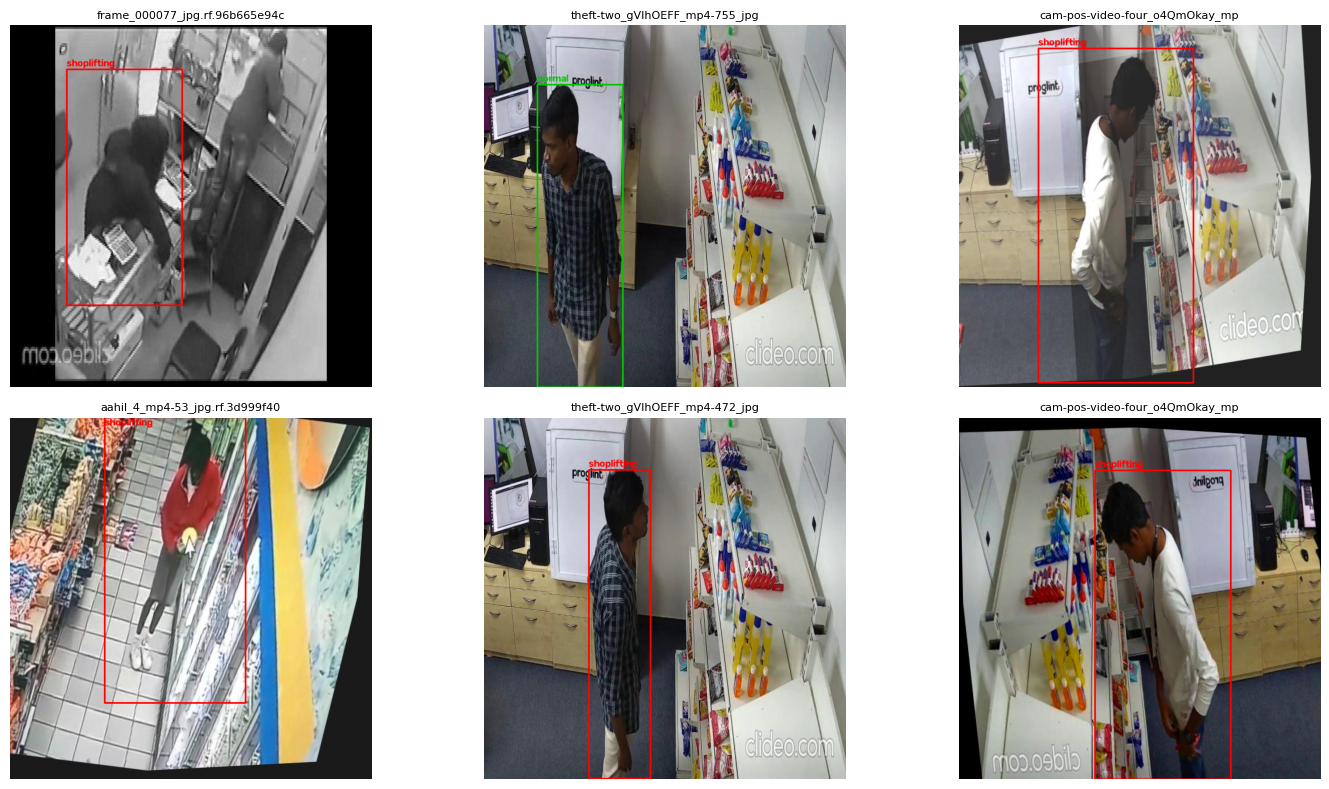

In [9]:
import random
import cv2
import matplotlib.pyplot as plt

train_images = sorted((dataset_dir / "train" / "images").glob("*"))
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, img_path in zip(axes.flat, random.sample(train_images, 6)):
    img = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    label_path = dataset_dir / "train" / "labels" / f"{img_path.stem}.txt"

    if label_path.exists():
        for line in label_path.read_text().splitlines():
            cls, xc, yc, bw, bh = map(float, line.split()[:5])
            x1, y1 = int((xc - bw / 2) * w), int((yc - bh / 2) * h)
            x2, y2 = int((xc + bw / 2) * w), int((yc + bh / 2) * h)
            color = (255, 0, 0) if data["names"][int(cls)] == "shoplifting" else (0, 200, 0)
            cv2.rectangle(img, (x1, y1), (x2, y2), color, 2)
            cv2.putText(img, data["names"][int(cls)], (x1, max(y1 - 5, 15)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.6, color, 2)

    ax.imshow(img)
    ax.set_title(img_path.name[:30], fontsize=8)
    ax.axis("off")

plt.tight_layout()
plt.show()

## 5. Train
Starts from COCO-pretrained weights (transfer learning). Built-in augmentation is left at Ultralytics defaults; if your Roboflow version is already heavily augmented, consider lowering them.

If you get an out-of-memory error, change `cache="ram"` to `cache=False`.

In [10]:
model = YOLO("yolo26n.pt")

model.train(
    data=str(data_yaml),
    epochs=EPOCHS,
    imgsz=IMG_SIZE,
    batch=-1,             # auto-select the largest batch size that fits in GPU memory
    patience=PATIENCE,
    seed=SEED,
    deterministic=True,
    cache="ram",          # faster loading; use cache=False if you run out of RAM
    name=RUN_NAME,
    exist_ok=False,       # error instead of silently overwriting an earlier run
    plots=True,           # saves confusion matrix, PR curves, sample predictions
)

# Ask the trainer where it saved the results instead of guessing the folder layout
run_dir = Path(model.trainer.save_dir)
best_weights = Path(model.trainer.best)
print("Run folder:  ", run_dir)
print("Best weights:", best_weights)

Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Shoplifting-Detection-1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo26n_v1, nbs=64, nms=None, opset=None, optimi

### Training curves and confusion matrix

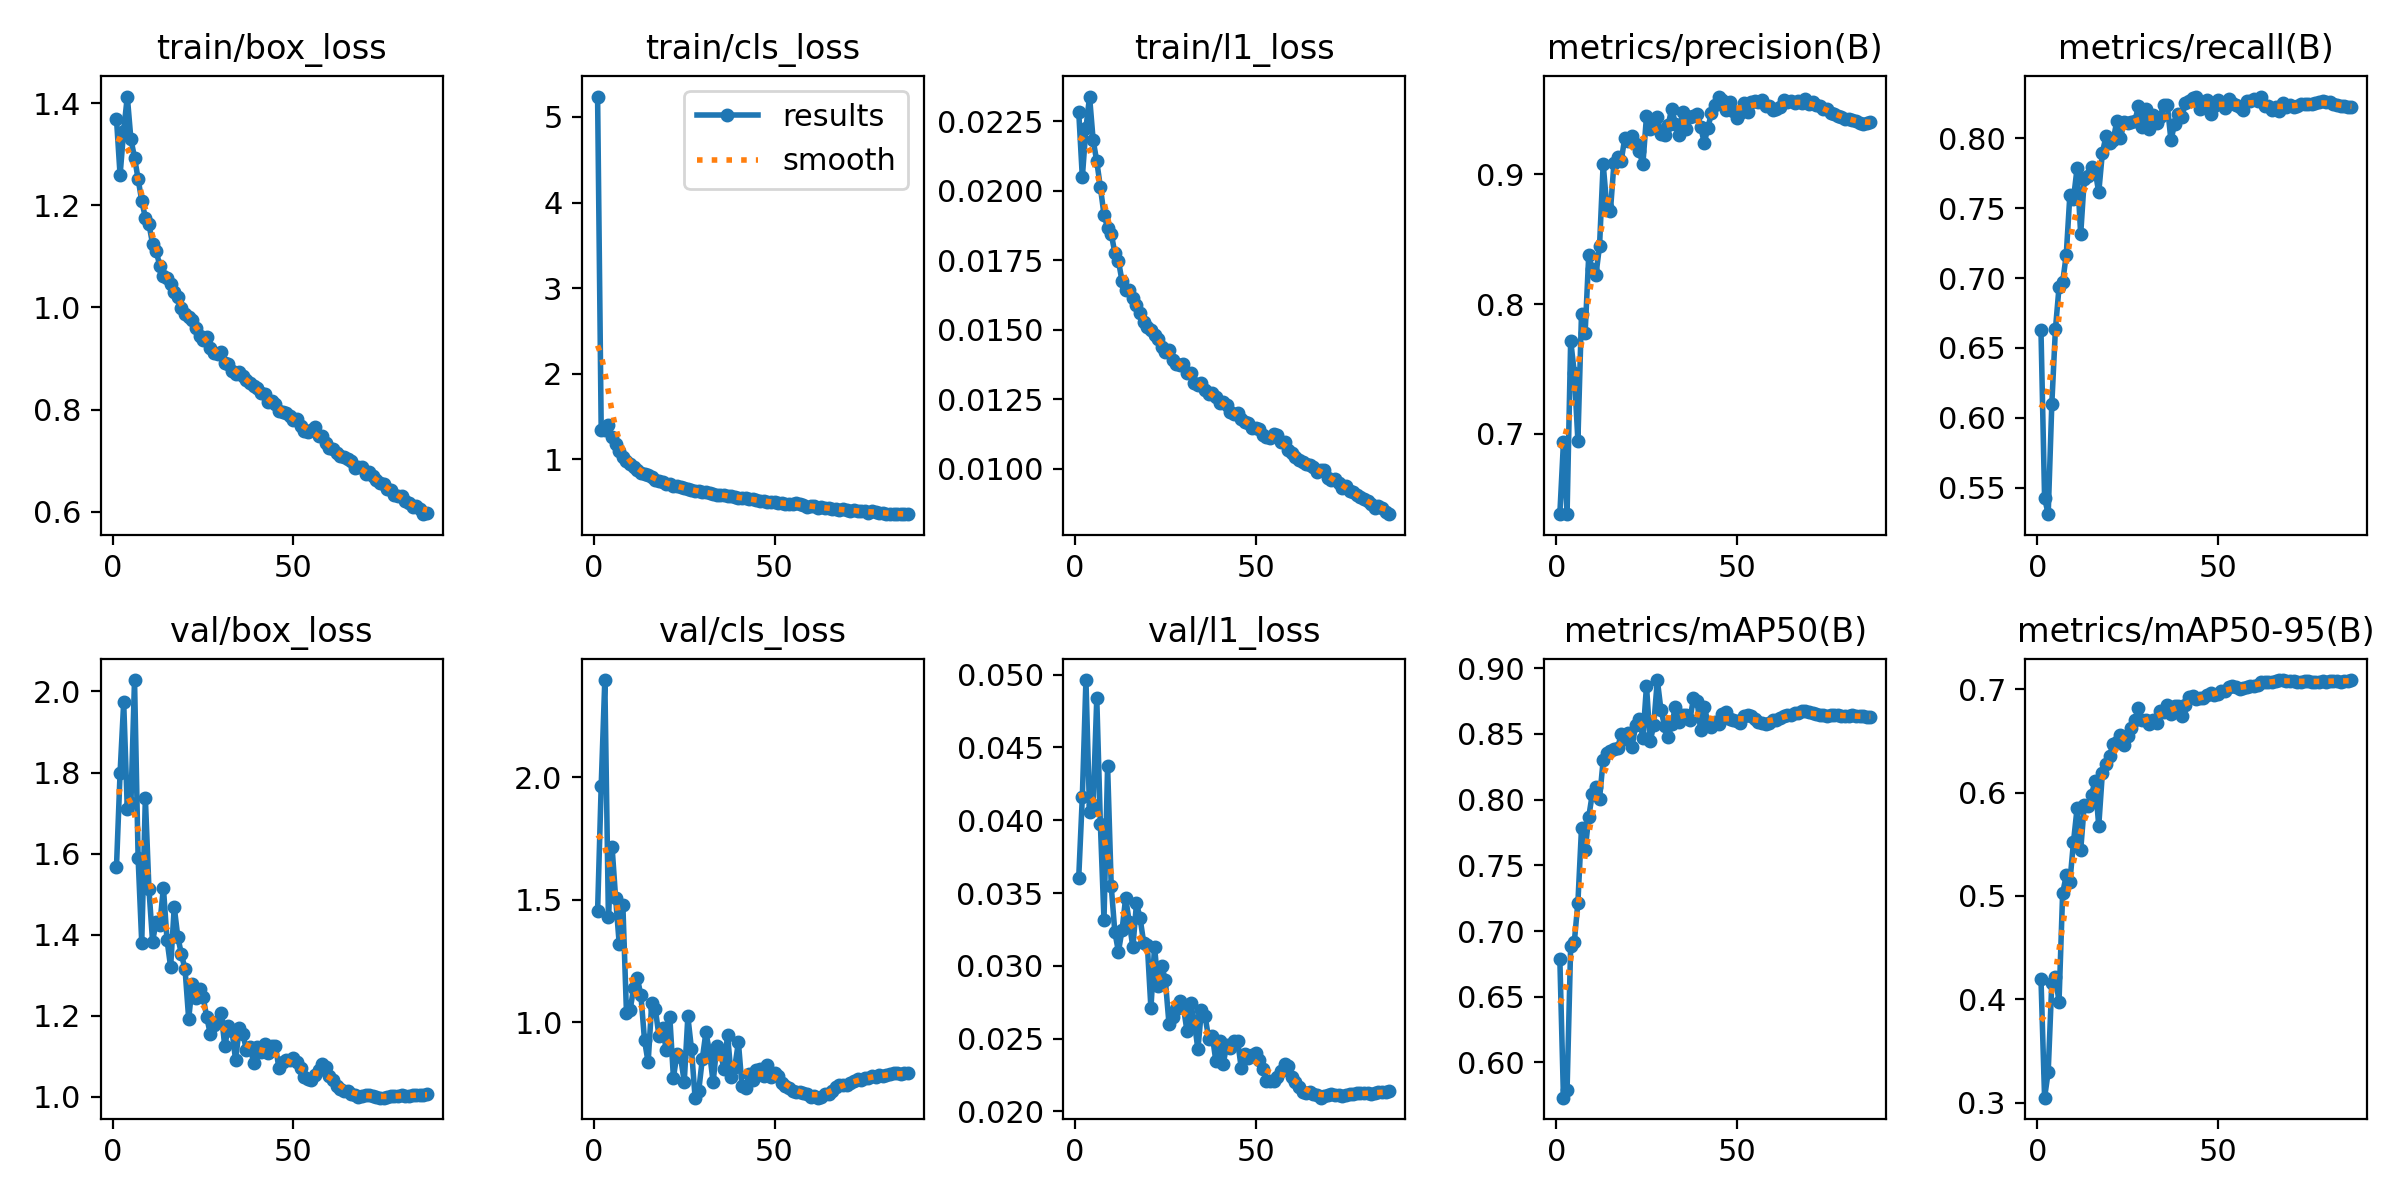

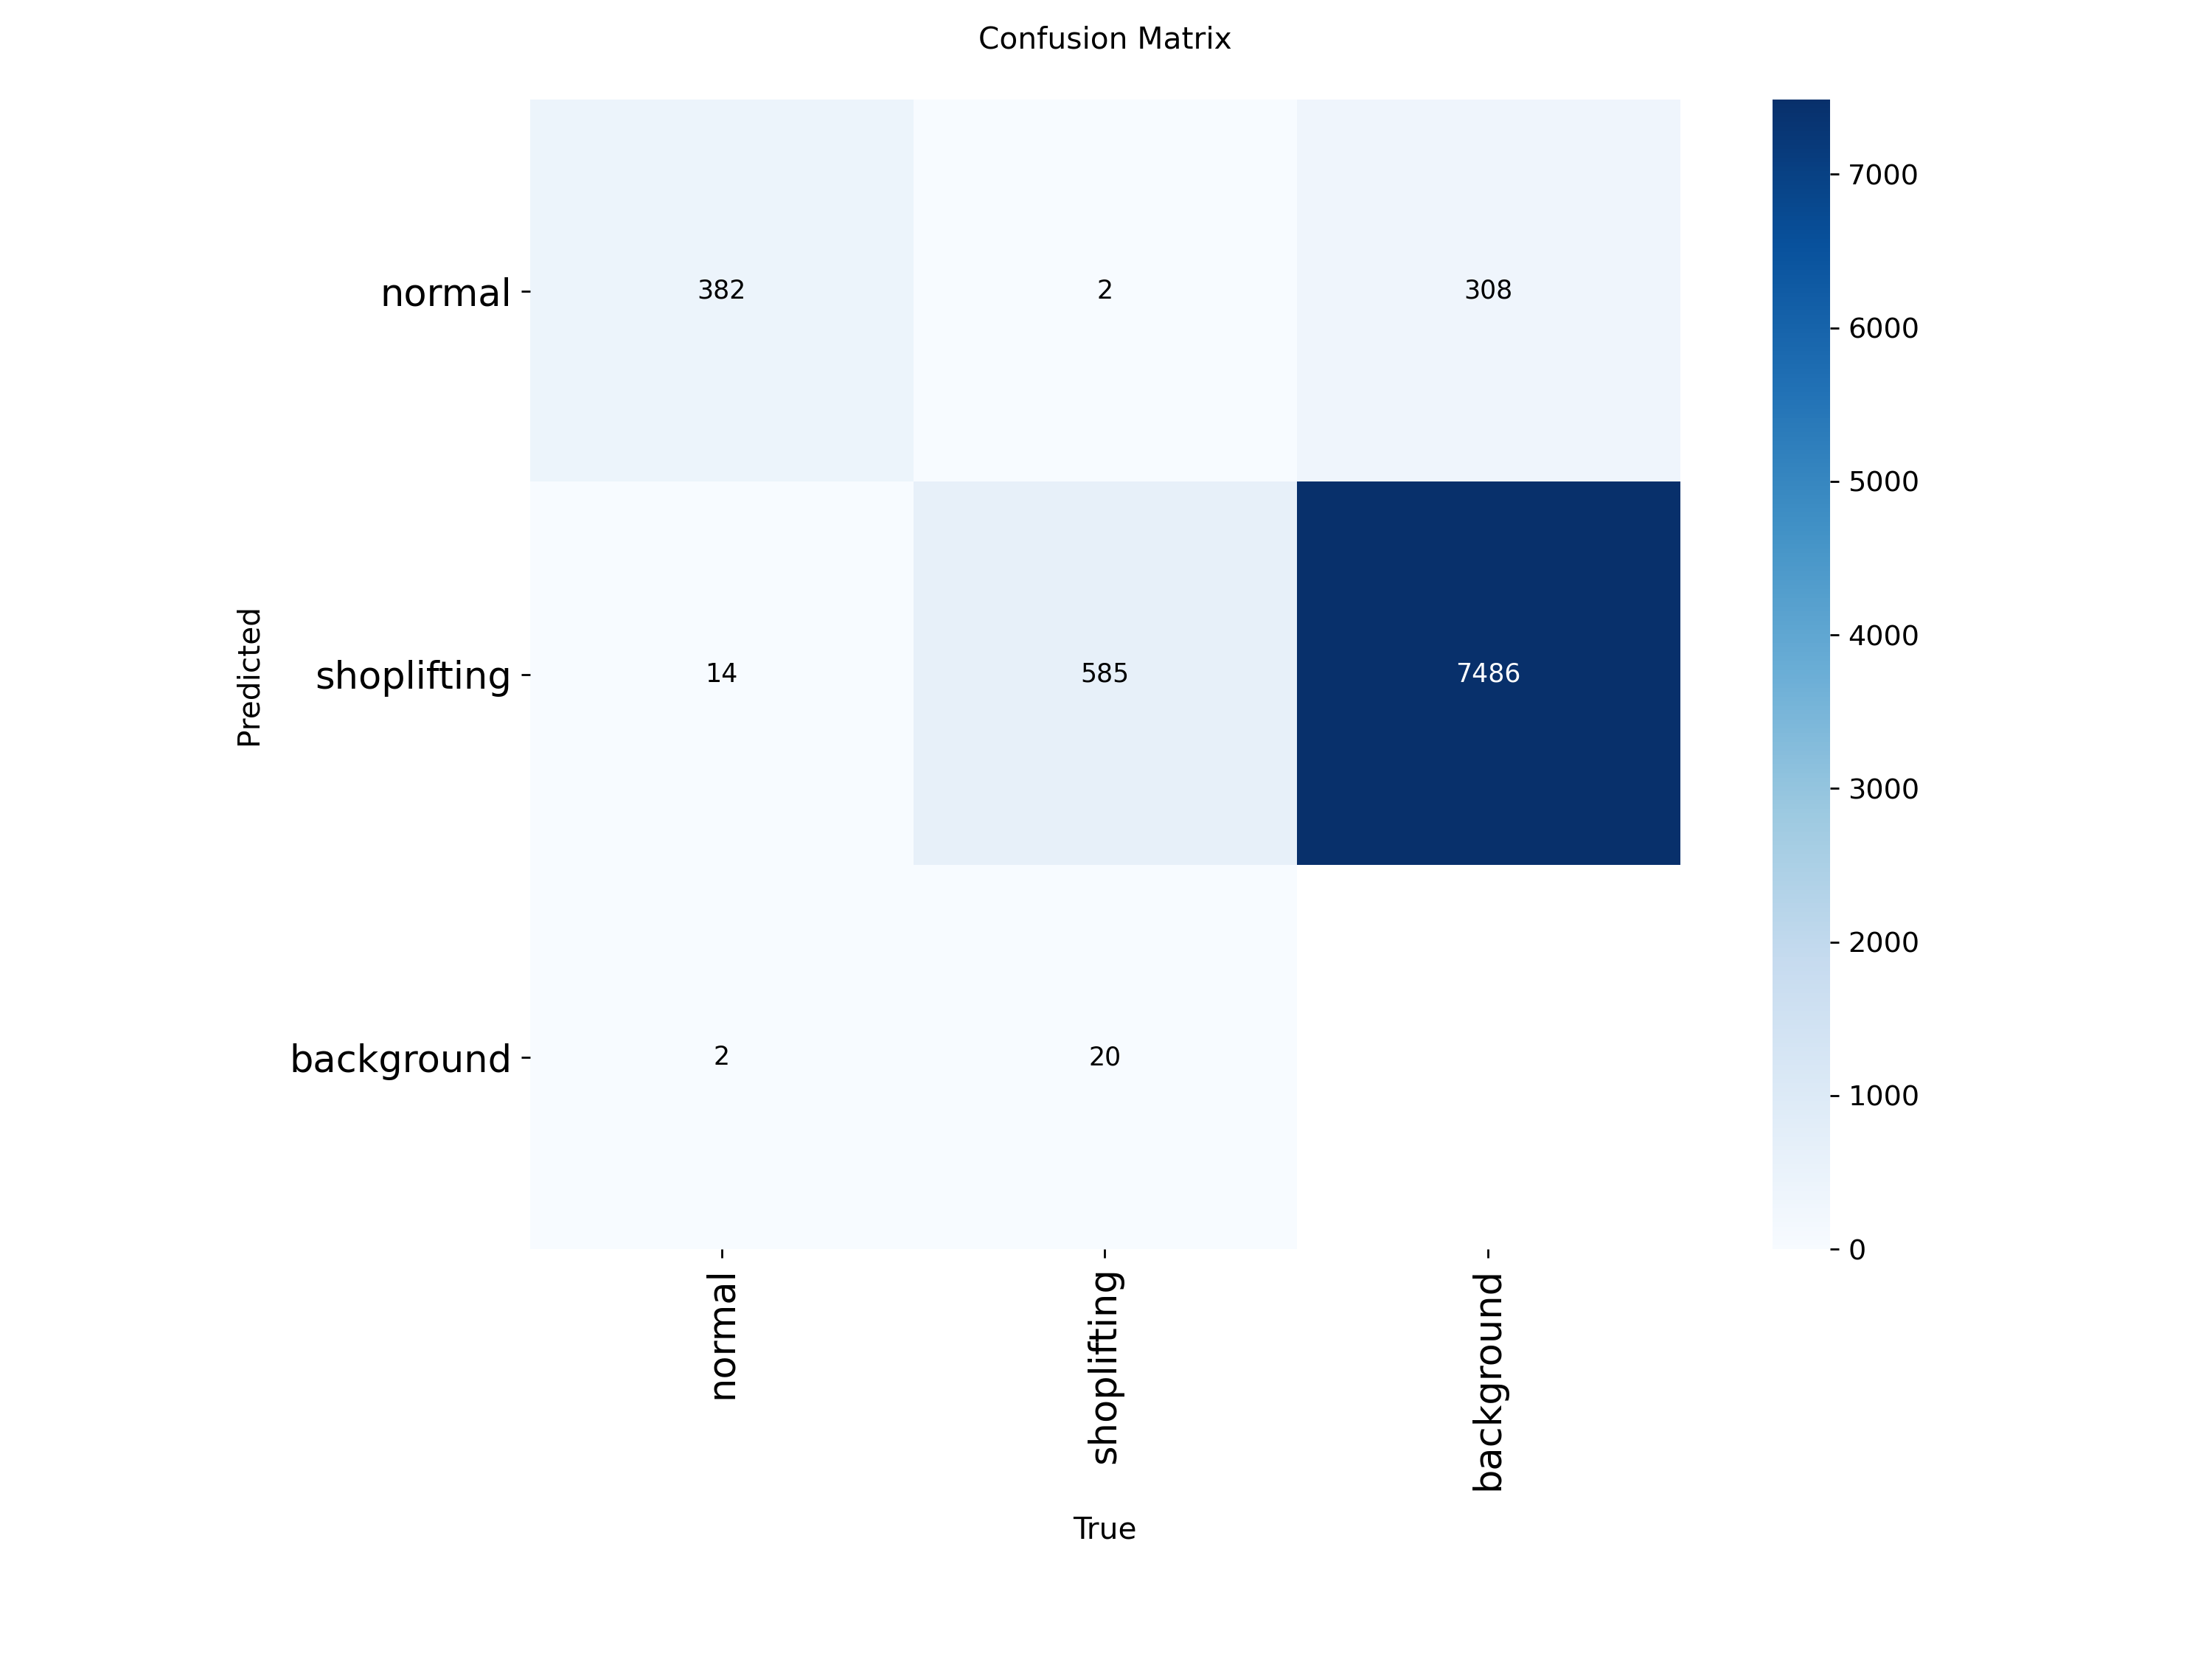

In [11]:
from IPython.display import Image, display

for chart in ("results.png", "confusion_matrix.png"):
    chart_path = run_dir / chart
    if chart_path.exists():
        display(Image(filename=str(chart_path), width=900))

## 6. Evaluate on the test split
These images were never used during training. **Recall on `shoplifting`** is the most important number: it shows how many real incidents the model catches.

In [12]:
best_model = YOLO(best_weights)
metrics = best_model.val(data=str(data_yaml), split="test", imgsz=IMG_SIZE)

print(f"\nTest mAP50:    {metrics.box.map50:.3f}")
print(f"Test mAP50-95: {metrics.box.map:.3f}")
for i, name in best_model.names.items():
    precision, recall, ap50, ap = metrics.box.class_result(i)
    print(f"{name:>12}: precision={precision:.3f}  recall={recall:.3f}  AP50={ap50:.3f}")

Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,389,978 parameters, 0 gradients, 5.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 23.9±13.9 MB/s, size: 67.8 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/Shoplifting-Detection-1/test/labels... 909 images, 3 backgrounds, 4 corrupt: 100% ━━━━━━━━━━━━ 909/909 490.0it/s 1.9s
val: /content/Shoplifting-Detection-1/test/images/Shoplifting001_x264_13_mp4-10_jpg.rf.bd5b97e53d6bacb778705e65cd563f12.jpg: ignoring corrupt image/label: labels mix segment and detection rows
val: /content/Shoplifting-Detection-1/test/images/Shoplifting001_x264_13_mp4-13_jpg.rf.fd2a0a89555a82dc18225c0be8457207.jpg: ignoring corrupt image/label: labels mix segment and detection rows
val: /content/Shoplifting-Detection-1/test/images/Shoplifting001_x264_

### Optional: predictions on a few test images

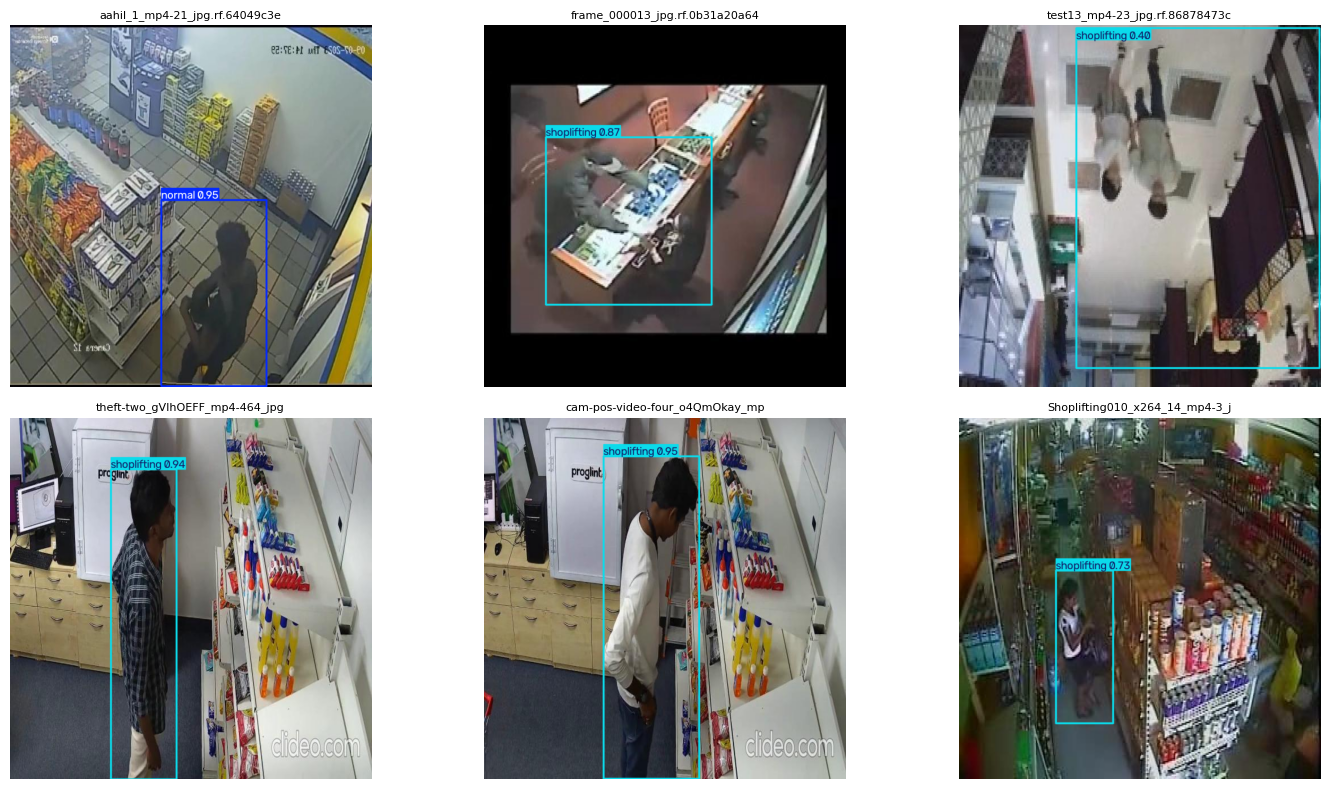

In [13]:
test_images = sorted((dataset_dir / "test" / "images").glob("*"))
results = best_model.predict(random.sample(test_images, 6), imgsz=IMG_SIZE, conf=0.25, verbose=False)

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, result in zip(axes.flat, results):
    ax.imshow(result.plot()[:, :, ::-1])  # plot() returns BGR; convert to RGB
    ax.set_title(Path(result.path).name[:30], fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 7. Export to ONNX
The ONNX model is what the CPU desktop app will use.

In [14]:
onnx_path = best_model.export(format="onnx", imgsz=IMG_SIZE)
print("ONNX model:", onnx_path)

Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO26n summary (fused): 121 layers, 2,389,978 parameters, 0 gradients, 5.4 GFLOPs

PyTorch: starting from '/content/runs/detect/yolo26n_v1/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 6, 8400) (5.2 MB)

ONNX: starting export with onnx 1.23.2 opset 18...
ONNX: slimming with onnxslim 0.1.98...
ONNX: export success ✅ 2.2s, saved as '/content/runs/detect/yolo26n_v1/weights/best.onnx' (9.4 MB)

Export complete (2.7s)
Results saved to /content/runs/detect/yolo26n_v1/weights/best.onnx
Predict:         yolo predict task=detect model=/content/runs/detect/yolo26n_v1/weights/best.onnx imgsz=640 
Validate:        yolo val task=detect model=/content/runs/detect/yolo26n_v1/weights/best.onnx imgsz=640 data=/content/Shoplifting-Detection-1/da

## 8. Measure CPU speed of the ONNX model
Colab CPUs differ from shop PCs, so re-run this on a low-end PC before release.

In [15]:
onnx_model = YOLO(onnx_path, task="detect")
speed_images = test_images[:50]

onnx_model.predict(speed_images[0], device="cpu", imgsz=IMG_SIZE, verbose=False)  # warm-up run

start = time.perf_counter()
for img in speed_images:
    onnx_model.predict(img, device="cpu", imgsz=IMG_SIZE, verbose=False)
ms_per_image = (time.perf_counter() - start) / len(speed_images) * 1000

print(f"CPU speed: {ms_per_image:.1f} ms/image (~{1000 / ms_per_image:.1f} FPS)")

Loading /content/runs/detect/yolo26n_v1/weights/best.onnx for ONNX Runtime inference...
Using ONNX Runtime 1.31.1 with CPUExecutionProvider
CPU speed: 82.0 ms/image (~12.2 FPS)


## 9. Save the results
Colab deletes files when the session ends. Either download the zip, or copy the run folder to Google Drive.

In [16]:
import shutil

zip_path = shutil.make_archive(RUN_NAME, "zip", run_dir)
print("Saved:", zip_path)

try:
    from google.colab import files
    files.download(zip_path)
except ImportError:
    pass  # running locally: the zip is already on disk

Saved: /content/yolo26n_v1.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [17]:
# Optional: copy the run folder to Google Drive instead
# from google.colab import drive
# drive.mount("/content/drive")
# shutil.copytree(run_dir, f"/content/drive/MyDrive/shoplifting_models/{RUN_NAME}")